In [129]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Задание 1

In [130]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

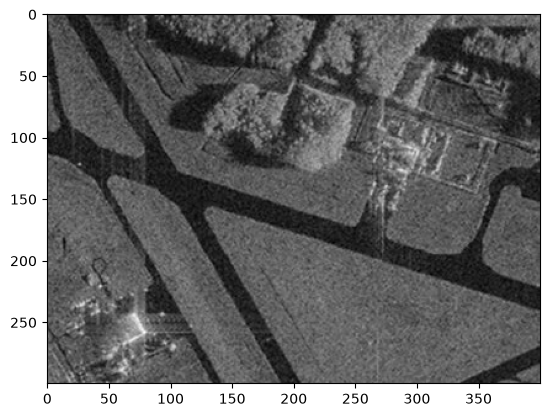

In [131]:
plt.imshow(image_gray, cmap="gray")

In [132]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False


In [133]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask*255


In [134]:
# ДЗ 1: подобранные параметры, чтобы выделить весь участок газона
# seed_point = (250,250) - точка внутри газона
# r = 3 - окно соседства, рост "перешагивает" через отдельные шумные пиксели SAR-снимка
# T = 20 - покрывает разброс яркости газона из-за спекл-шума, но меньше перепада газон/дорога
seed_point = (250,250)
mask = region_growing(image_gray,seed_point,homo_average,3, 20)

33
83
134
179
228
274
327
378
421
484
519
574
618
664
717
602
571
585
598
605
591
577
574
557
528
534
522
508
492
477
456
442
435
404
449
379
360
332
323
299
281
260
251
242
230
213
199
189
148
81
75
67
64
63
57
51
44
36
29
19
11
0


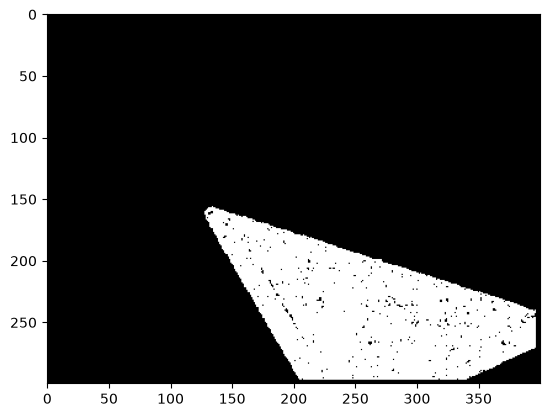

In [135]:
plt.imshow(mask, cmap="gray")

# Задание 2

In [136]:
# критерий на основе медианы: точка сравнивается не со средним, а с медианой яркости региона
def homo_med(img, mask, point, T):
    med_val = np.median(img[mask>0])

    if abs(med_val - img[point]) <= T:
        return True

    return False


In [137]:
# те же параметры, что в ДЗ 1, меняется только критерий
seed_point = (250,250)
mask2 = region_growing(image_gray,seed_point,homo_med,3, 20)

33
83
135
179
228
274
328
378
431
475
520
585
619
669
720
606
547
585
598
605
591
579
575
559
571
537
522
509
495
477
456
444
435
406
395
379
360
332
323
300
282
260
252
242
230
213
199
189
148
81
75
67
64
151
57
51
44
38
30
19
13
0


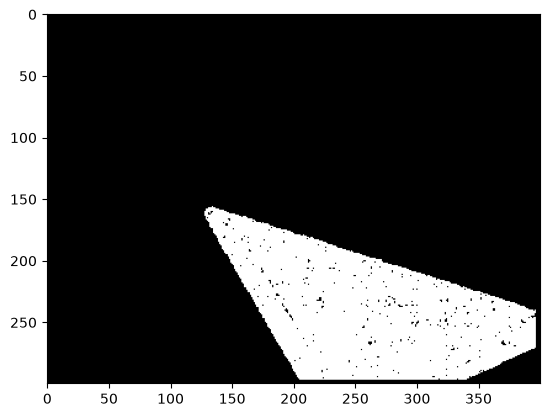

In [138]:
plt.imshow(mask2, cmap="gray")

  homo_med сравнивает точку не со средним, а с медианой яркости региона.
  При тех же параметрах (r = 3, T = 20) оба критерия выделяют один и тот же газон,
  результаты почти совпадают. Медиана меньше реагирует на отдельные очень яркие/темные
  пиксели спекл-шума, но на этом снимке разница почти не видна.

# Задание 3

In [139]:
image_palm = cv2.imread('palms.jpg')
image_palm_gray = cv2.cvtColor(image_palm, cv2.COLOR_BGR2GRAY)

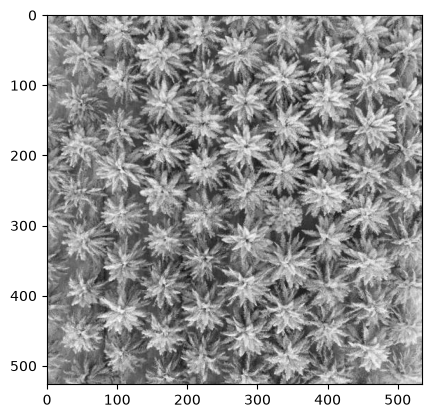

In [140]:
plt.imshow(image_palm_gray, cmap="gray")

In [ ]:
image_palm_blur = cv2.GaussianBlur(image_palm_gray, (25,25), 0)
ret, thresh_palm = cv2.threshold(image_palm_blur,0,255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)

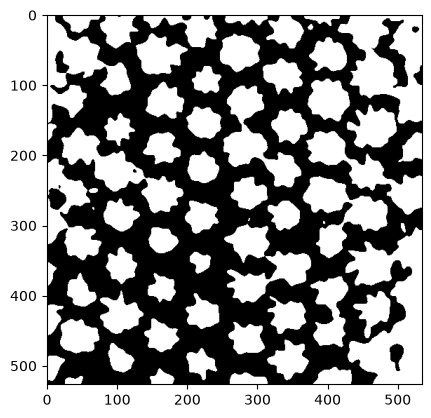

In [142]:
plt.imshow(thresh_palm, cmap="gray")

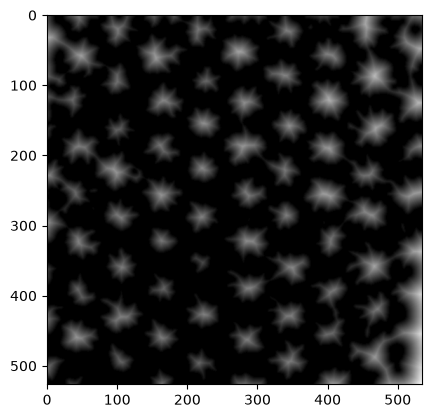

In [143]:
dist_palm = cv2.distanceTransform(thresh_palm, cv2.DIST_L2, 5)
plt.imshow(dist_palm, cmap="gray")

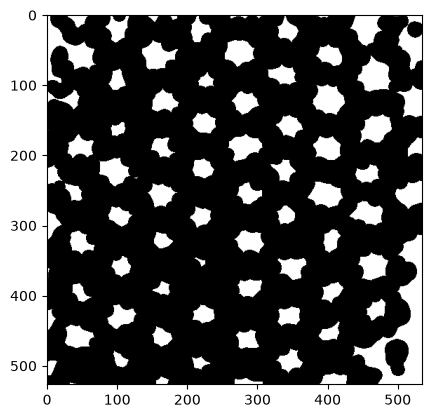

In [144]:
ret, sure_fg_palm = cv2.threshold(dist_palm, 0.2 * dist_palm.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg_palm, cmap="gray")

In [145]:
sure_fg_palm = sure_fg_palm.astype(np.uint8)

In [ ]:
ret, markers_palm = cv2.connectedComponents(sure_fg_palm)
num_palms = ret - 1 
print(f"Количество пальм: {num_palms}")

Количество пальм: 84


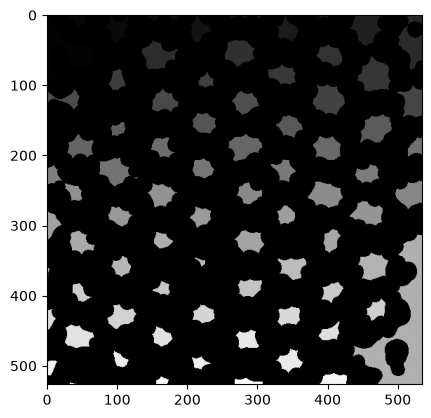

In [147]:
plt.imshow(markers_palm, cmap="gray")

In [148]:
markers_palm = cv2.watershed(image_palm, markers_palm)

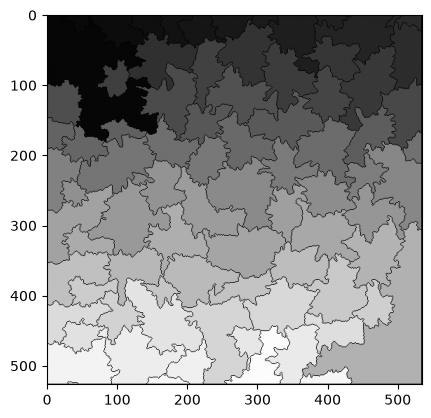

In [149]:
plt.imshow(markers_palm, cmap="gray")